**Changed on branch `feature/downtime-drivers`:** the `tkinter` file picker was replaced by `data_utils.load_*()`, which reads the parquet file from the repository root, so the notebook runs without clicking and is reproducible. `inplace=True` was removed (deprecated in pandas 3). Pump make/model and facility are no longer dropped (they are only excluded from the old XGBoost inputs). See the notes after the PCA results and before the XGBoost section.

In [1]:
import pandas as pd

import data_utils as du

daily_production = du.load_daily()
daily_production.head(10)

,uwi,formatted_uwi,well_name,field_operating_area,province,surface_latitude,surface_longitude,on_production_date,facility_name,well_daily_status,...,choke_open_pct,pcp_pump_name,pcp_pump_make,pcp_pump_model,pcp_pump_displacement_m3d100rpm,pcp_pump_rpm,pcp_pump_comment,pcp_pump_electric_current_a,pcp_pump_rod_torque_ftlb,pcp_pump_volume_throughput_m3d
0,100142303701W400,100/14-23-037-01W4/00,100/14-23-037-01W4/00,Bodo East,AB,52.1963470,-110.0553380,2018-10-02,NaN,Producing,...,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN
1,141092703528W300,141/09-27-035-28W3/00,141/09-27-035-28W3/00 INJ,Cactus Lake,SK,52.0367781,-109.9092225,1980-07-19,Cactus EOR 12-21 Polymer Injection,Injecting,...,100.0,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN
2,111152503528W300,111/15-25-035-28W3/00,(15A15-25) - 111/15-25-035-28W3/00,Cactus Lake,SK,52.0397797,-109.8680742,2014-08-24,Cactus Lake 16-27-035-28W3 BTY,Producing,...,NaN,111/15-25/00 PCP Pump,MANTL,6M-1800,6.0,385,NaN,NaN,NaN,23.1
3,192031104225W300,192/03-11-042-25W3/00,(12D14-11) - 192/03-11-042-25W3/00,Winter,SK,52.6090814,-109.4933142,1999-10-30,12-32 BTY Facility,Producing,...,NaN,(12D14-11) PCP Pump,MANTL,102-900,102.0,355,NaN,50.0,660.0000,362.1
4,191063103527W300,191/06-31-035-27W3/00,(4B06-31) - 191/06-31-035-27W3/00,Cactus Lake,SK,52.0466803,-109.8507078,2015-12-23,Cactus Lake 16-27-035-28W3 BTY,Suspended,...,NaN,191/06-31/00 PCP Pump,MANTL,127-M1200,127.0,270,NaN,NaN,NaN,342.9
5,191092704125W300,191/09-27-041-25W3/00,(8B02-34) - 191/09-27-041-25W3/00,Winter,SK,52.5669875,-109.5149864,2015-07-24,12-32 BTY Facility,Producing,...,NaN,(8B02-34) PCP Pump,Weatherford,106-1200,106.0,425,NaN,74.0,740.0000,450.5
6,111010503526W300,111/01-05-035-26W3/00,(A01-05) - 111/01-05-035-26W3/00 INJ,Plover Lake Conventional,SK,51.9699639,-109.6708033,None,PLOVER LAKE SWD A11-5-035-26W3,Injecting,...,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN
7,121120603526W300,121/12-06-035-26W3/00,121/12-06-035-26W3/00,Plover Lake Conventional,SK,51.9771714,-109.7151739,1997-06-23,WAS NORCEN PLOVER LK B12-6,Suspended,...,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN
8,106052704225W300,106/05-27-042-25W3/00,(8D06-27) - 106/05-27-042-25W3/00,Winter,SK,52.6457303,-109.5171839,2017-02-01,12-32 BTY Facility,Producing,...,NaN,(8D06-27) PCP Pump,BMW Pump,56-1200,56.0,55,2018-Jun-02,37.0,2507.7113,30.8
9,191132703420W300,191/13-27-034-20W3/00,191/13-27-034-20W3/00,Druid Main,SK,51.9449597,-108.7634600,2014-08-17,NaN,Producing,...,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN


In [2]:
# get data schema
daily_production.dtypes

uwi                                    str
formatted_uwi                          str
well_name                              str
field_operating_area                   str
province                               str
surface_latitude                    object
surface_longitude                   object
on_production_date                  object
facility_name                          str
well_daily_status                      str
primary_fluid_type                     str
flow_direction                         str
production_date                     object
hours_down                         float64
hours_on_prod                      float64
lost_oil_m3                        float64
downtime_code_1                        str
downtime_code_2                        str
downtime_code_3                        str
tubing_pressure_kpa                float64
casing_pressure_kpa                float64
injection_pressure_kpa             float64
well_status                            str
oil_produce

In [3]:
daily_production[['choke_open_pct', 'hydraulic_pressure_psi', 'tubing_pressure_kpa']]

,choke_open_pct,hydraulic_pressure_psi,tubing_pressure_kpa
0,NaN,NaN,NaN
1,100.0,NaN,NaN
2,NaN,500.0,700.00
3,NaN,NaN,900.00
4,NaN,NaN,NaN
...,...,...,...
5075585,NaN,NaN,NaN
5075586,NaN,NaN,NaN
5075587,NaN,NaN,2068.43
5075588,NaN,NaN,2000.00


In [4]:
daily_production['tubing_pressure_kpa'].value_counts(dropna=False).sort_index()

tubing_pressure_kpa
-13.79           1671
-1.00            1359
-0.11               1
-0.03               2
 0.00          424418
               ...   
 44052.00           1
 56495.60           4
 110040.00          3
 999999.00          7
 NaN          2407337
Name: count, Length: 11500, dtype: int64

In [5]:
# remove unimportant columns
# pcp_pump_make, pcp_pump_model and facility_name are now KEPT: they are needed to compare
# failure rates by pump model and facility (see downtime_drivers.ipynb).
daily_production = daily_production.drop(columns=[
"formatted_uwi", "well_name", "well_status", "pcp_pump_name", "pcp_pump_comment",
"downtime_code_1", "hours_on_prod"
])

In [6]:
daily_production.columns

Index(['uwi', 'field_operating_area', 'province', 'surface_latitude',
       'surface_longitude', 'on_production_date', 'facility_name',
       'well_daily_status', 'primary_fluid_type', 'flow_direction',
       'production_date', 'hours_down', 'lost_oil_m3', 'downtime_code_2',
       'downtime_code_3', 'tubing_pressure_kpa', 'casing_pressure_kpa',
       'injection_pressure_kpa', 'oil_produced_m3', 'gas_produced_e3m3',
       'injection_volume_m3', 'injected_water_m3', 'injected_polymer_m3',
       'pump_efficiency_pct', 'water_produced_m3', 'hydraulic_pressure_psi',
       'choke_open_pct', 'pcp_pump_make', 'pcp_pump_model',
       'pcp_pump_displacement_m3d100rpm', 'pcp_pump_rpm',
       'pcp_pump_electric_current_a', 'pcp_pump_rod_torque_ftlb',
       'pcp_pump_volume_throughput_m3d'],
      dtype='str')

In [7]:
daily_production_for_encoding = daily_production.drop(columns=["uwi", "field_operating_area", "province", "production_date", "on_production_date"])

In [8]:

daily_production_encoded = pd.get_dummies(daily_production_for_encoding, columns=["well_daily_status", "primary_fluid_type", "flow_direction", "downtime_code_2", "downtime_code_3"], dtype="uint8")
daily_production_encoded.columns


Index(['surface_latitude', 'surface_longitude', 'facility_name', 'hours_down',
       'lost_oil_m3', 'tubing_pressure_kpa', 'casing_pressure_kpa',
       'injection_pressure_kpa', 'oil_produced_m3', 'gas_produced_e3m3',
       ...
       'downtime_code_3_Water Source Supply', 'downtime_code_3_Waxed Up',
       'downtime_code_3_Weather Conditions', 'downtime_code_3_Well Loaded',
       'downtime_code_3_Well Optimization/Stimulation',
       'downtime_code_3_Well Stimulation', 'downtime_code_3_Well Torqued',
       'downtime_code_3_Wellhead Drive/Stuffing',
       'downtime_code_3_Wellhead Drive/Stuffing Box',
       'downtime_code_3_Workover'],
      dtype='str', length=243)

## PCA pipeline and diagnostics

This section standardizes the numeric features, imputes missing values, and uses PCA for dimensionality reduction and contribution analysis.

In [9]:
# PCA setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Use only numeric columns. get_dummies should produce numeric columns, but this also
# protects PCA from any remaining text/category fields.
pca_data = daily_production_encoded.select_dtypes(include="number").copy()

# Remove constant columns: they have no variance and therefore contribute nothing to PCA.
constant_columns = pca_data.columns[pca_data.nunique(dropna=True) <= 1]
pca_data = pca_data.drop(columns=constant_columns)

print(f"Rows: {len(pca_data):,}")
print(f"Numeric, non-constant features: {pca_data.shape[1]:,}")
print(f"Missing values: {int(pca_data.isna().sum().sum())}")


Rows: 5,075,590
Numeric, non-constant features: 237


Missing values: 54373113


In [10]:
# A large dataframe can make exact, dense PCA expensive. Use a reproducible sample
# for PCA exploratory analysis, while keeping the final pipeline easy to reuse on
# other subsets or batches of the same data.
PCA_SAMPLE_SIZE = 100_000
analysis_sample = pca_data.sample(
    n=min(PCA_SAMPLE_SIZE, len(pca_data)),
    random_state=42,
)

# Keep enough components for a useful scree plot. The upper bound is also valid
# for the randomized solver used below.
explained_component_limit = min(
    50,
    analysis_sample.shape[0] - 1,
    analysis_sample.shape[1],
)

exploration_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(
        n_components=explained_component_limit,
        svd_solver="randomized",
        random_state=42,
    )),
])

X_exploration = exploration_pipeline.fit_transform(analysis_sample)
exploration_pca = exploration_pipeline.named_steps["pca"]
explained_variance = exploration_pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print(f"Analyzed sample size: {len(analysis_sample):,}")
print(f"Components plotted: {len(explained_variance)}")
print(f"Variance explained in the plotted components: {cumulative_variance[-1]:.2%}")


Analyzed sample size: 100,000
Components plotted: 50
Variance explained in the plotted components: 54.20%


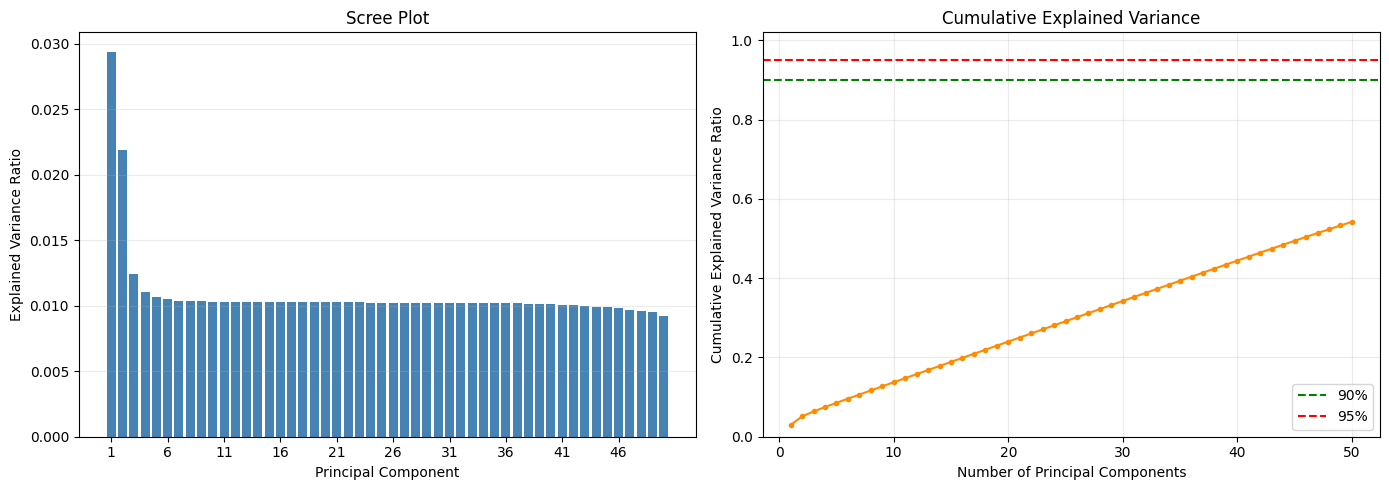

More than 50 components are needed to reach 90%; increase the component limit
More than 50 components are needed to reach 95%; increase the component limit


In [11]:
# Scree and cumulative explained variance plots
pc_numbers = np.arange(1, len(explained_variance) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(pc_numbers, explained_variance, color="steelblue")
axes[0].set_title("Scree Plot")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_xticks(pc_numbers[::max(1, len(pc_numbers) // 10)])
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(pc_numbers, cumulative_variance, marker="o", markersize=3, color="darkorange")
axes[1].axhline(0.90, color="green", linestyle="--", label="90%")
axes[1].axhline(0.95, color="red", linestyle="--", label="95%")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance Ratio")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Suggested dimensions under common 90% and 95% variance targets.
for target in (0.90, 0.95):
    needed = int(np.searchsorted(cumulative_variance, target) + 1)
    if needed <= len(cumulative_variance):
        print(f"At least {needed} components are needed to reach {target:.0%} of variance")
    else:
        print(f"More than {len(cumulative_variance)} components are needed to reach {target:.0%}; increase the component limit")


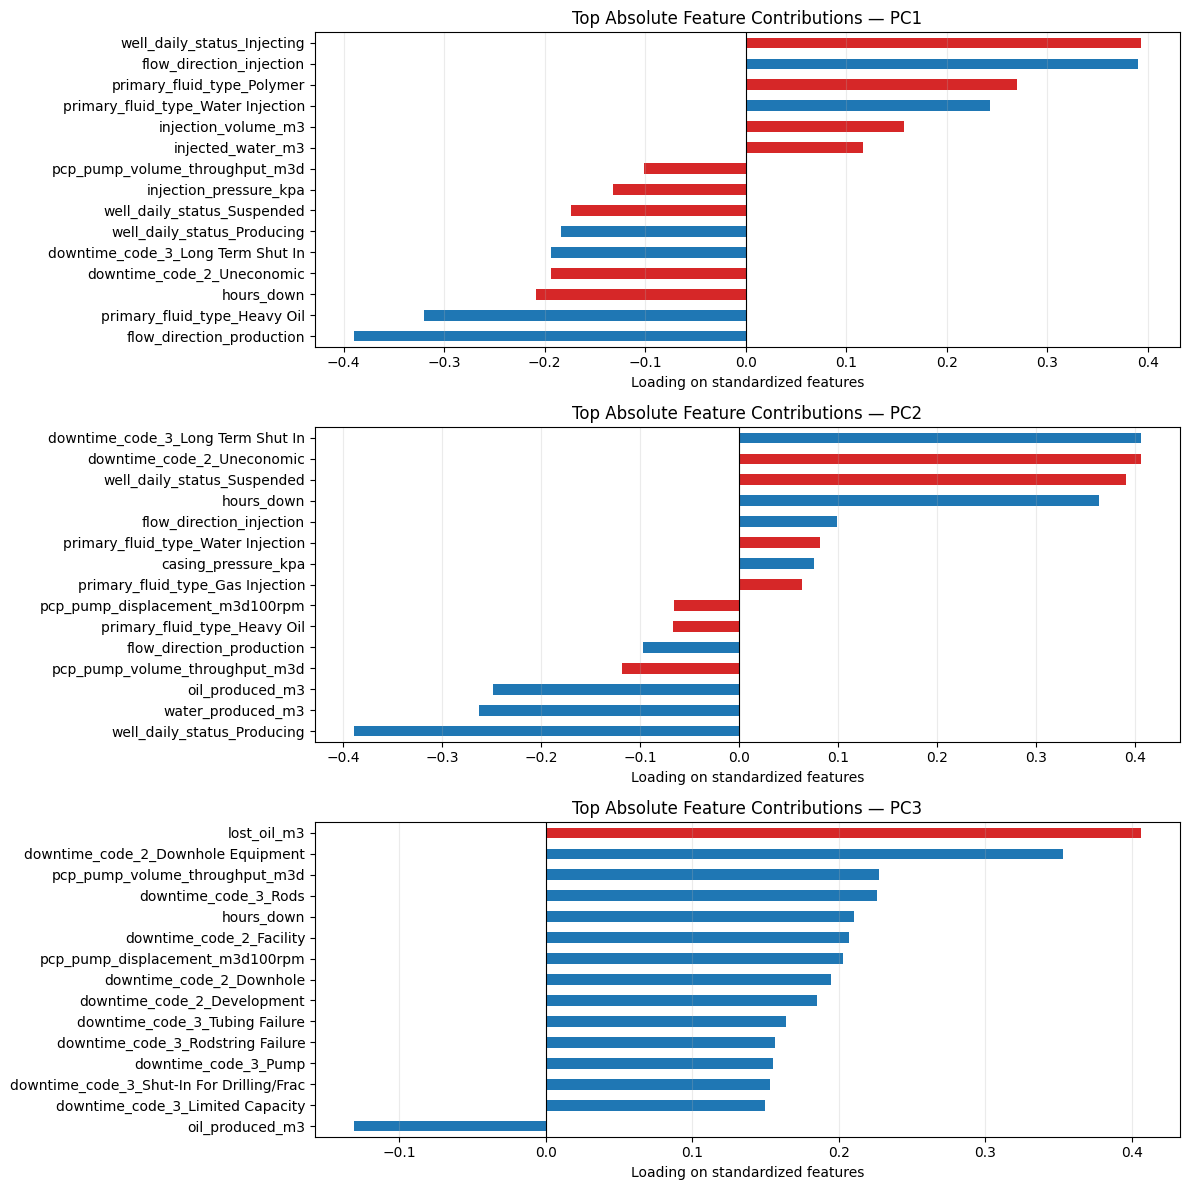


PC1 top absolute loadings


,feature,loading
0,well_daily_status_Injecting,0.392878
1,flow_direction_injection,0.390225
2,flow_direction_production,-0.389302
3,primary_fluid_type_Heavy Oil,-0.319703
4,primary_fluid_type_Polymer,0.270176
5,primary_fluid_type_Water Injection,0.243201
6,hours_down,-0.208711
7,downtime_code_2_Uneconomic,-0.193942
8,downtime_code_3_Long Term Shut In,-0.193748
9,well_daily_status_Producing,-0.183871



PC2 top absolute loadings


,feature,loading
0,downtime_code_3_Long Term Shut In,0.405955
1,downtime_code_2_Uneconomic,0.405782
2,well_daily_status_Suspended,0.391122
3,well_daily_status_Producing,-0.389024
4,hours_down,0.364208
5,water_produced_m3,-0.263269
6,oil_produced_m3,-0.249065
7,pcp_pump_volume_throughput_m3d,-0.118396
8,flow_direction_injection,0.098521
9,flow_direction_production,-0.097638



PC3 top absolute loadings


,feature,loading
0,lost_oil_m3,0.406144
1,downtime_code_2_Downhole Equipment,0.353395
2,pcp_pump_volume_throughput_m3d,0.227172
3,downtime_code_3_Rods,0.226384
4,hours_down,0.210426
5,downtime_code_2_Facility,0.207039
6,pcp_pump_displacement_m3d100rpm,0.202544
7,downtime_code_2_Downhole,0.194340
8,downtime_code_2_Development,0.185055
9,downtime_code_3_Tubing Failure,0.163773


In [12]:
# PCA loadings show how strongly each standardized, numeric feature contributes to
# each principal component. Absolute loadings are used for ranking.
feature_names = pca_data.columns.to_numpy()
loadings = exploration_pca.components_.T

n_plot_components = min(3, loadings.shape[1])
fig, axes = plt.subplots(n_plot_components, 1, figsize=(12, 4 * n_plot_components))
if n_plot_components == 1:
    axes = [axes]

for pc_index, ax in enumerate(axes):
    pc_loadings = pd.Series(loadings[:, pc_index], index=feature_names)
    top_loadings = pc_loadings.reindex(pc_loadings.abs().sort_values(ascending=False).head(15).index)

    colors = ["tab:red" if value < 0 else "tab:blue" for value in top_loadings]
    top_loadings.sort_values().plot.barh(ax=ax, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Top Absolute Feature Contributions — PC{pc_index + 1}")
    ax.set_xlabel("Loading on standardized features")
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# Compact ranking table for the first few PCs.
for pc_index in range(n_plot_components):
    ranking = pd.Series(loadings[:, pc_index], index=feature_names)
    print(f"\nPC{pc_index + 1} top absolute loadings")
    display(pd.DataFrame({
        "feature": ranking.abs().sort_values(ascending=False).head(15).index,
        "loading": ranking.loc[ranking.abs().sort_values(ascending=False).head(15).index].values,
    }))


Final PCA uses 50 components to reach approximately 95% variance
Final components explain 54.20% of variance


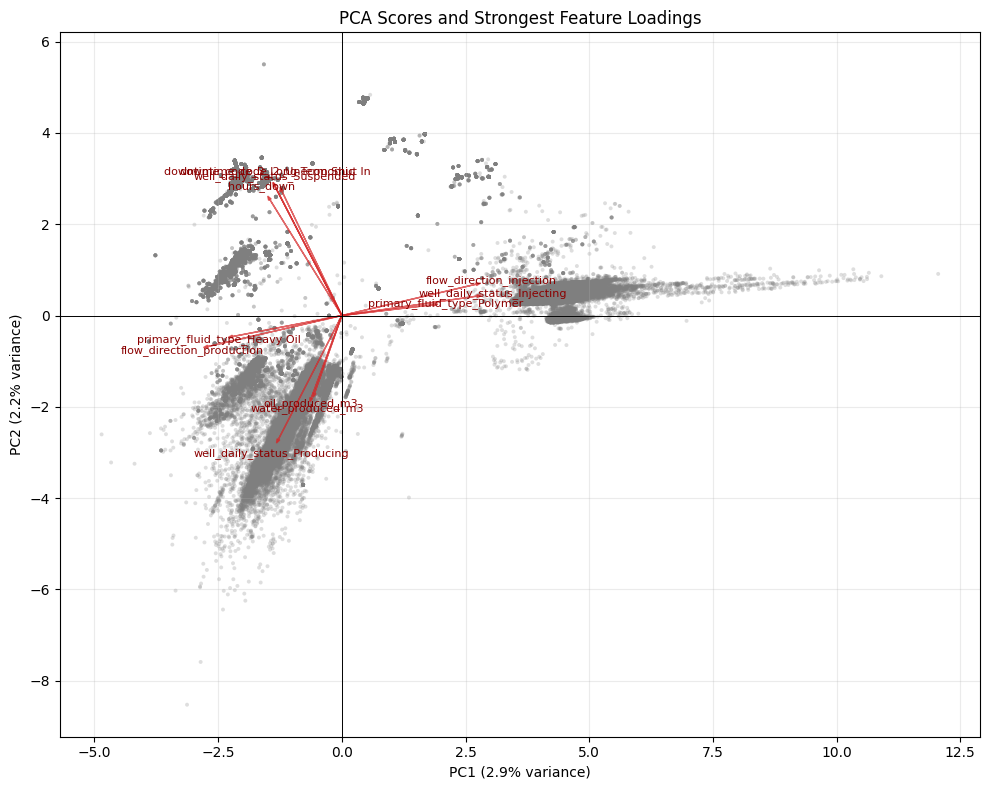

In [13]:
# Final PCA pipeline: preserve at least 95% of variance when the exploratory
# scree plot reaches that target. The integer component count is required by the
# randomized solver in this scikit-learn version.
components_for_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)
if components_for_95 > len(cumulative_variance):
    components_for_95 = len(cumulative_variance)

# To reuse it on the full dataframe: final_pca_pipeline.transform(pca_data)
final_pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(
        n_components=components_for_95,
        svd_solver="randomized",
        random_state=42,
    )),
])

X_final_sample = final_pca_pipeline.fit_transform(analysis_sample)
final_pca = final_pca_pipeline.named_steps["pca"]

print(f"Final PCA uses {final_pca.n_components_} components to reach approximately 95% variance")
print(f"Final components explain {final_pca.explained_variance_ratio_.sum():.2%} of variance")

# PC1 vs PC2 biplot, showing only the strongest loading vectors.
pc1 = X_final_sample[:, 0]
pc2 = X_final_sample[:, 1]

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(pc1, pc2, s=8, alpha=0.25, edgecolors="none", color="tab:gray")

# Scale loadings to the score range for legibility.
final_loadings = final_pca.components_.T
loadings_pc1 = final_loadings[:, 0]
loadings_pc2 = final_loadings[:, 1]
strongest = np.argsort(np.hypot(loadings_pc1, loadings_pc2))[-12:]
score_scale = max(np.std(pc1), np.std(pc2))

for column_index in strongest:
    dx = loadings_pc1[column_index] * score_scale * 3
    dy = loadings_pc2[column_index] * score_scale * 3
    ax.arrow(0, 0, dx, dy, head_width=score_scale * 0.025,
             length_includes_head=True, alpha=0.7, color="tab:red")
    ax.text(dx * 1.08, dy * 1.08, str(feature_names[column_index]),
            fontsize=8, ha="center", va="center", color="darkred")

ax.axhline(0, color="black", linewidth=0.7)
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlabel(f"PC1 ({final_pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({final_pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("PCA Scores and Strongest Feature Loadings")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**What the PCA actually shows (added note):** PC1 separates **injectors from producers** (`flow_direction`, `well_daily_status_Injecting`, fluid type) and PC2 separates **shut-in from producing** wells (`Uneconomic` / `Long Term Shut In`, `hours_down`, volumes). 50 components explain only ~54% of the variance, because most columns are sparse one-hot dummies and ~54M missing values were median-imputed. So PCA does not give usable features here. Its main lesson is that **well types must be analysed separately**, which is why the downtime analysis uses oil producers only.

---


> **Superseded: see `datasets/downtime_drivers.ipynb` (section 3.1 B).** The model below is kept as the team's first attempt, but its SHAP ranking should not be presented, for four reasons:
> 1. **Random split:** `train_test_split` shuffles days, so the model trains on days after the ones it is tested on.
> 2. **Same-day leakage:** same-day `oil_produced_m3`, `water_produced_m3` and pump throughput are inputs. A well that is down produces nothing, so these restate the target.
> 3. **`head(100_000)` is not a random sample:** it is whatever order the file is stored in.
> 4. **Injectors are mixed in** with producers, although downtime and lost oil only apply to producers.
>
> The new notebook fixes all four (chronological split, previous-day and trend features only, whole-well data, oil producers only) and compares the model with a naive baseline.

# Features affecting oil loss and downtime hours
using XGBoost and SHAP feature importance to determine which features are more important in influencing both targets

# <mark><b>CHANGE CODE TO INSTEAD USE ALL OF THE DATA (or at least the 2M rows) LATER ON!</b></mark>
- drop all nulls for y target variables since XGBoost doesn't work if they are null

In [14]:
# use 10k rows only to speed up training and SHAP analysis (for now)
daily_prod_sample = daily_production.head(100_000)

In [15]:
# some extra data cleaning
daily_prod_sample = daily_prod_sample[daily_prod_sample['tubing_pressure_kpa'] != 999999] # drop placeholder rows

# set colums to proper datatypes for XGBoost
num_cols_to_fix = ['pcp_pump_rpm', 'surface_latitude', 'surface_longitude'] 
cat_cols_to_fix = ['primary_fluid_type', 'flow_direction'] 

for col in num_cols_to_fix:
    daily_prod_sample[col] = pd.to_numeric(daily_prod_sample[col], errors='coerce')

for col in cat_cols_to_fix:
    daily_prod_sample[col] = daily_prod_sample[col].astype('category')

In [16]:
# check and remove nulls in targets (lost_oil_m3 and hours_down)
print(daily_prod_sample['lost_oil_m3'].isna().sum())
print(daily_prod_sample['hours_down'].isna().sum(), "\n") # hours is good

print(daily_prod_sample['lost_oil_m3'].value_counts(dropna=False).sort_index(), '\n')

67407
0 

lost_oil_m3
0.000000     24828
0.000604         2
0.000856         8
0.002735         1
0.004317         7
             ...  
24.018330        1
26.958691        1
28.676338        1
34.694284        1
NaN          67407
Name: count, Length: 3320, dtype: int64 



In [17]:
# simply remove the null columns, as i still have 32k rows left to work with and is ok, 2M+ rows will be the case in the real XGBoost so its fine
daily_prod_sample = daily_prod_sample.dropna(subset=['lost_oil_m3'])
print(daily_prod_sample['lost_oil_m3'].value_counts(dropna=False))

lost_oil_m3
0.000000    24828
0.337530       58
0.486577       47
0.038727       46
0.545893       40
            ...  
0.765208        1
0.663400        1
5.463185        1
0.123602        1
1.407383        1
Name: count, Length: 3319, dtype: int64


In [18]:
import xgboost as xgb
import shap
from sklearn.model_selection import train_test_split, RandomizedSearchCV

# define target and features
X = daily_prod_sample.drop(columns=['lost_oil_m3', 
                                    'hours_down', 
                                    'on_production_date', 
                                    'production_date', 
                                    'uwi', 
                                    'field_operating_area', 
                                    'province', 
                                    'downtime_code_2', 
                                    'downtime_code_3', 
                                    'well_daily_status',
                                    # text columns kept for other analyses; not model inputs here
                                    'pcp_pump_make', 'pcp_pump_model', 'facility_name'])

y_oil_loss = daily_prod_sample['lost_oil_m3']
y_hours_down = daily_prod_sample['hours_down']

# train test split for each target variable
X_train, X_test, y_oil_loss_train, y_oil_loss_test = train_test_split(X, y_oil_loss, test_size=0.2, random_state=42)
X_train, X_test, y_hours_down_train, y_hours_down_test = train_test_split(X, y_hours_down, test_size=0.2, random_state=42)

# run hyperparamater tuning for optimal model results
params = { # test parameters for XGBoost
    "n_estimators": [50, 100, 200, 400, 500, 600],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "max_depth": [2,4,6,8],
    "min_child_weight": [1,3,5,7]
}

def tune_xgboost(Xtrain, Ytrain): # define function to run a base XGBoost model, then run hyperparameter tuning and fit to optimal params
    base = xgb.XGBRegressor(
        enable_categorical = True,
        tree_method='hist',
        random_state=42,
    )

    search = RandomizedSearchCV(
        estimator=base,
        param_distributions=params,
        n_iter=25,
        cv=5,
        random_state=42,
        n_jobs=-1
    )

    search.fit(Xtrain, Ytrain)
    return search.best_estimator_, search.best_params_

# run XGBoost + tuning on both targets
xg_oil_loss, oil_params = tune_xgboost(X_train, y_oil_loss_train)
xg_hours_down, hour_params = tune_xgboost(X_train, y_hours_down_train)

# SHAP analysis for each model
explainer_oil_loss = shap.Explainer(xg_oil_loss)
shap_values_oil_loss = explainer_oil_loss(X_test)

explainer_hours_down = shap.Explainer(xg_hours_down)
shap_values_hours_down = explainer_hours_down(X_test)

In [19]:
# test results
print("Best Oil_Loss Results:", oil_params)
print("Best Hours_Down Results:", hour_params)

Best Oil_Loss Results: {'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.05}
Best Hours_Down Results: {'n_estimators': 400, 'min_child_weight': 7, 'max_depth': 6, 'learning_rate': 0.05}


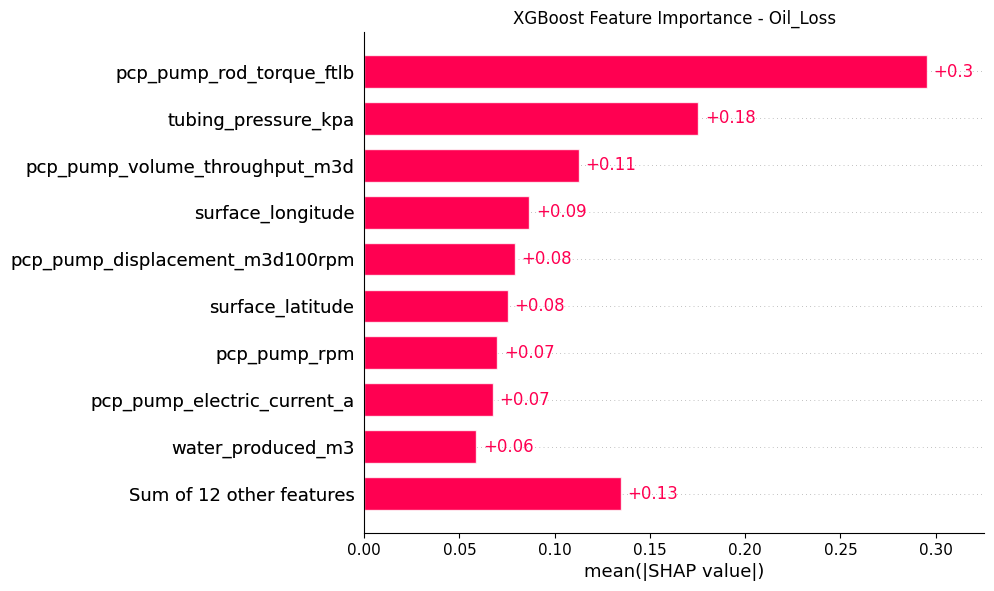

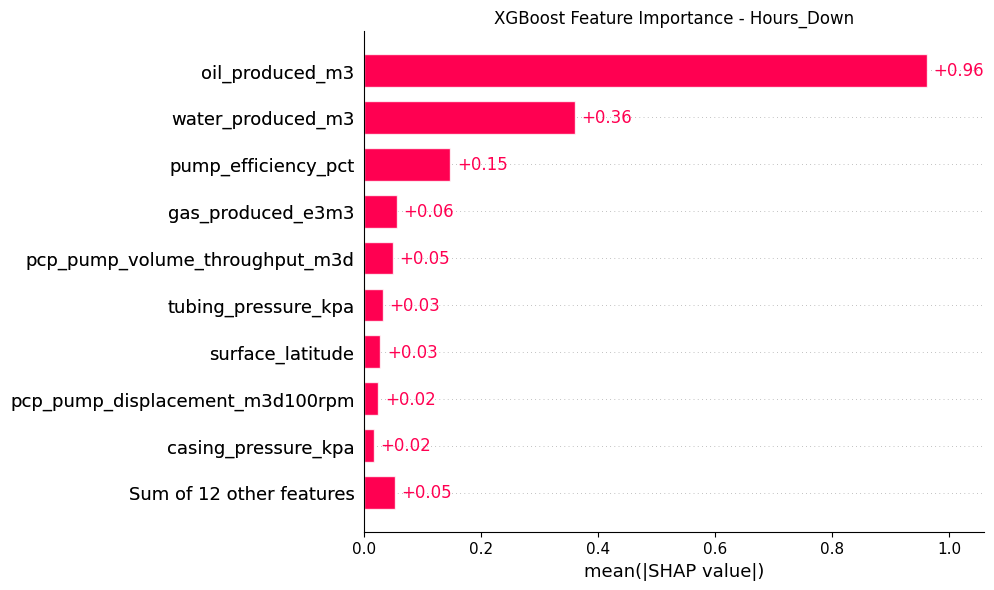

In [20]:
# visualize predictor rankings
import matplotlib.pyplot as plt

# plot SHAP values
plt.title('XGBoost Feature Importance - Oil_Loss')
shap.plots.bar(shap_values_oil_loss)

plt.title('XGBoost Feature Importance - Hours_Down')
shap.plots.bar(shap_values_hours_down)